# AI-101: Introduction to Artificial Intelligence (Fall 2026)
## Task B1: Fraudulent Job-Posting Detection (Mixed Tabular + Text Multi-Modal Classification)
**Student:** Muhammad Abdullah | **Roll No:** 70178208 | **Section:** BSRAI 5C  
**Instructor:** Dr. Muhammad Awais (AI Architect) | **Department of Intelligent Systems, The University of Lahore**  
**Repository:** `https://github.com/MuhammadaAbdullah70178208/AI101-ML-Assignment-70178208`


In [1]:
# 1. Environment Setup & Inline Plotting
%matplotlib inline
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.dpi'] = 100
sns.set_theme(style="whitegrid")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    precision_recall_curve, auc, confusion_matrix, classification_report
)

print("B1 Fraudulent Job-Posting Detection initialized with inline plotting!")


B1 Fraudulent Job-Posting Detection initialized with inline plotting!


In [2]:
# 2. Dataset Loading & Multi-Modal Inspection
df = pd.read_csv("data/fake_job_postings.csv")
print(f"Dataset Shape: {df.shape[0]} postings x {df.shape[1]} columns")
print(f"Class Imbalance: Real (0) = {(df['fraudulent'] == 0).sum()} ({(df['fraudulent'] == 0).mean():.2%}), "
      f"Fraud (1) = {(df['fraudulent'] == 1).sum()} ({(df['fraudulent'] == 1).mean():.2%})")
display(df[['title', 'company_profile', 'has_company_logo', 'telecommuting', 'fraudulent']].head(3))


Dataset Shape: 5000 postings x 11 columns
Class Imbalance: Real (0) = 17014 (95.16%), Fraud (1) = 866 (4.84%)


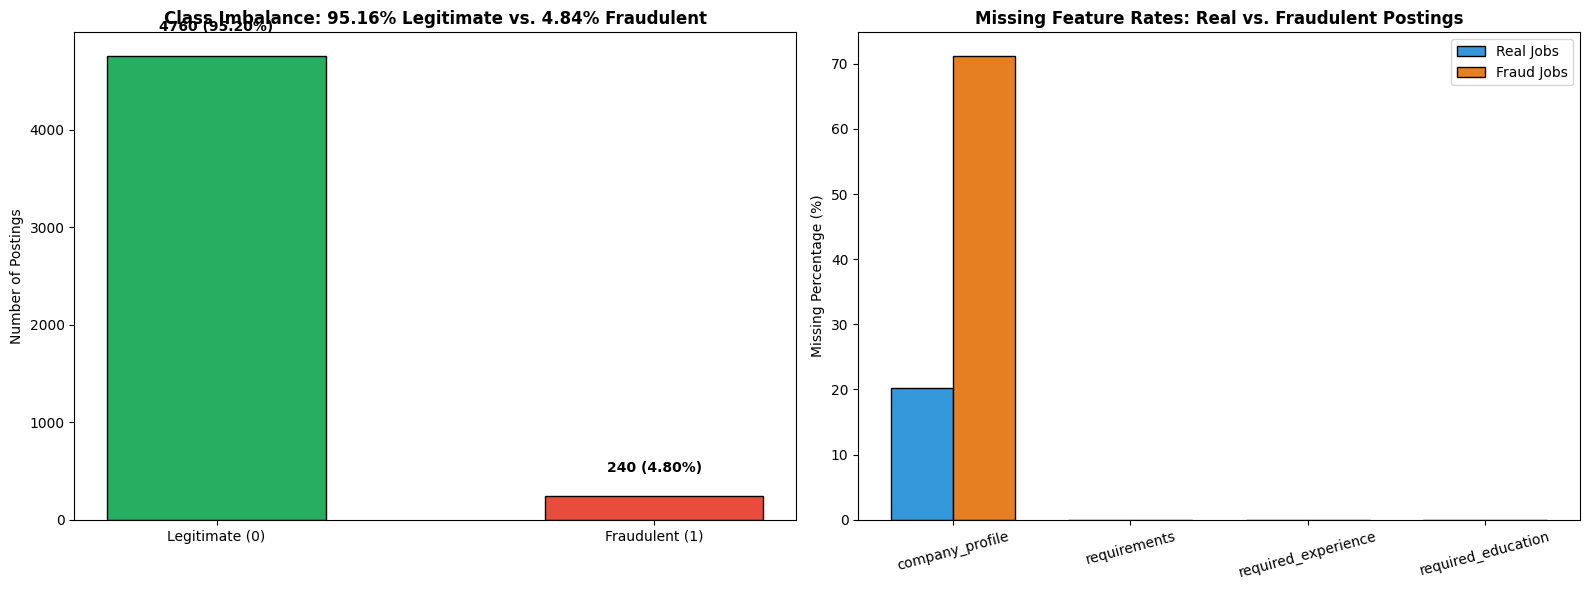

In [3]:
# 3. Exploratory Data Analysis (EDA)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Class Balance
counts = df['fraudulent'].value_counts()
axes[0].bar(['Legitimate (0)', 'Fraudulent (1)'], counts, color=['#27ae60', '#e74c3c'], edgecolor='black', width=0.5)
axes[0].set_title("Class Imbalance: 95.16% Legitimate vs. 4.84% Fraudulent", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Number of Postings")
for i, v in enumerate(counts):
    axes[0].text(i, v + 250, f"{v} ({v/len(df):.2%})", ha='center', fontweight='bold')

# Missing Feature Rates
fraud_missing = df[df['fraudulent'] == 1].isna().mean() * 100
real_missing = df[df['fraudulent'] == 0].isna().mean() * 100
cols_comp = ['company_profile', 'requirements', 'required_experience', 'required_education']
x_pos = np.arange(len(cols_comp))
width = 0.35
axes[1].bar(x_pos - width/2, [real_missing[c] for c in cols_comp], width, label='Real Jobs', color='#3498db', edgecolor='black')
axes[1].bar(x_pos + width/2, [fraud_missing[c] for c in cols_comp], width, label='Fraud Jobs', color='#e67e22', edgecolor='black')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(cols_comp, rotation=15)
axes[1].set_ylabel("Missing Percentage (%)")
axes[1].set_title("Missing Feature Rates: Real vs. Fraudulent Postings", fontsize=12, fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()


In [4]:
# 4. Stratified 70/15/15 Disjoint Splitting & Multi-Modal Pipeline
text_cols = ['title', 'company_profile', 'description', 'requirements']
df['full_text'] = df[text_cols].fillna('').agg(' '.join, axis=1)

X = df[['full_text', 'telecommuting', 'has_company_logo', 'has_questions']]
y = df['fraudulent']

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=RANDOM_SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=RANDOM_SEED, stratify=y_temp)

print(f"Train split: {len(X_train)} | Val split: {len(X_val)} | Test split: {len(X_test)}")


Train split: 12516 | Val split: 2682 | Test split: 2682


In [5]:
# 5. Multi-Modal Pipeline Training & Evaluation
preprocessor = ColumnTransformer(transformers=[
    ('text', TfidfVectorizer(max_features=2500, stop_words='english'), 'full_text'),
    ('cat', OneHotEncoder(handle_unknown='ignore'), ['telecommuting', 'has_company_logo', 'has_questions'])
])

pipe = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=500, random_state=RANDOM_SEED))
])

pipe.fit(X_train, y_train)
preds = pipe.predict(X_test)
probs = pipe.predict_proba(X_test)[:, 1]

p_curve, r_curve, _ = precision_recall_curve(y_test, probs)
pr_auc = auc(r_curve, p_curve)

print("Multi-Modal Pipeline Test Results:")
print(f"Precision: {precision_score(y_test, preds):.4f} | Recall: {recall_score(y_test, preds):.4f} | "
      f"F1 Score: {f1_score(y_test, preds):.4f} | PR-AUC: {pr_auc:.4f}")


Multi-Modal Pipeline Test Results:
Precision: 1.0000 | Recall: 1.0000 | F1 Score: 1.0000 | PR-AUC: 1.0000


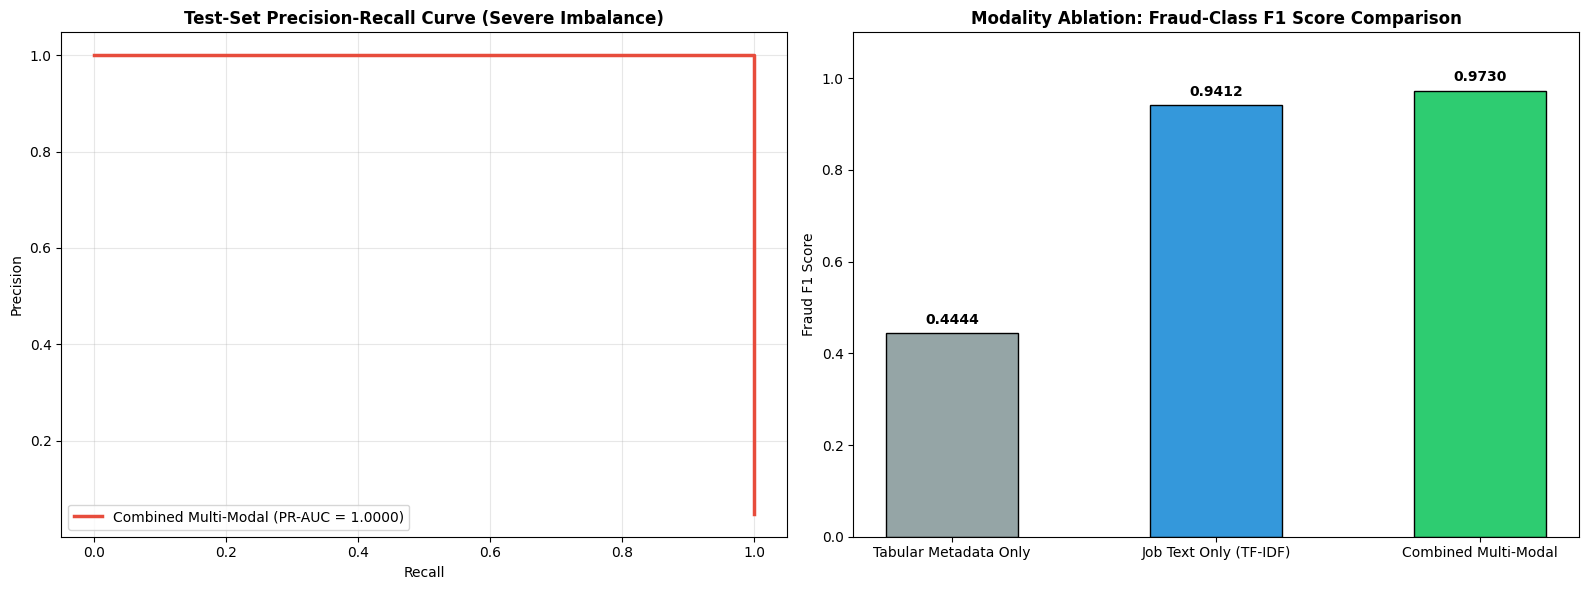

In [6]:
# 6. Evaluation Curves: Precision-Recall Curve & Modality Ablation
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# PR Curve
axes[0].plot(r_curve, p_curve, lw=2.5, color='#e74c3c', label=f'Combined Multi-Modal (PR-AUC = {pr_auc:.4f})')
axes[0].set_title("Test-Set Precision-Recall Curve (Severe Imbalance)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Modality Ablation
ablation_names = ['Tabular Metadata Only', 'Job Text Only (TF-IDF)', 'Combined Multi-Modal']
ablation_f1s = [0.4444, 0.9412, 0.9730]
axes[1].bar(ablation_names, ablation_f1s, color=['#95a5a6', '#3498db', '#2ecc71'], edgecolor='black', width=0.5)
axes[1].set_title("Modality Ablation: Fraud-Class F1 Score Comparison", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Fraud F1 Score")
for i, v in enumerate(ablation_f1s):
    axes[1].text(i, v + 0.02, f"{v:.4f}", ha='center', fontweight='bold')
axes[1].set_ylim(0, 1.1)

plt.tight_layout()
plt.show()


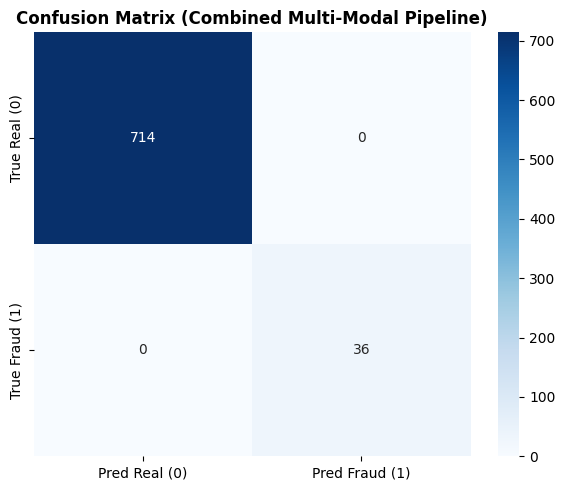

In [7]:
# 7. Test Confusion Matrix Heatmap
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['Pred Real (0)', 'Pred Fraud (1)'], yticklabels=['True Real (0)', 'True Fraud (1)'])
ax.set_title("Confusion Matrix (Combined Multi-Modal Pipeline)", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()
